# TD 2. Epidemic propagation on complex networks

*(designed for Jupyter lab, not Jupyter notebook.)*

## Import modules

In [3]:
from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets
from matplotlib import pyplot as plt
from IPython.display import display, clear_output
import numpy as np
import networkx as nx
rng = np.random.default_rng(12345) # random number generator

## Context

Let us consider the dynamic spread of a contagious disease using a simple propagation model. Our goal will not be to investigate the microscopic details of transmission, 
but instead the role played by the network of contacts.

We focus on propagation models of the S->I->X type, where X∈{∅,"S","R","R->S"}, with
- S: susceptible individual (= can be contaminated)
- I: infected individual (= can contaminate others)
- R: recovered after an infection and is currently immunised against the disease (note that death is equivalent to recovery in this sense, for all practical purposes...)

We consider that there exists an underlying network of contacts (not all of which leads to an infection). During the infection of a node, each contact is activated with a rate $\beta>0$, which means that for each time unit (e.g., for each day), each susceptible neighbour on the network becomes infected with probability $\beta$.

Contacts will be represented as black edges on the network, whereas infecting contacts will be shown in red. Susceptible nodes (S-nodes) will appear in green and I-nodes will be shown in red.
Numerically, nodes are stored in the dictionary "nodes", whose keys are the node identifier (ID) and the value are the node state: -1 if susceptible, -2 if recovered, t>=0 if the node has been infected at time "t". 
Similarly, edges are stored in a dictionary, with:
- key: (i,j), the nodes "i" and "j" **[!!! with $i<j$ !!!]** that are connected
- value: -1 for a simple contact, t>=0 if this has been an infectious contact at time "t".

In [4]:
### GENERATE A RANDOM NETWORK AS AN EXAMPLE ###
N= 20 # number of nodes
nodes= {}
for n in range(N):
    nodes[n]= -1 # state of the node; -1: susceptible; t: infected at  time t; -2: X (recovered or dead)
edges= {}
for i in range(N):
    for j in range(i):
        if rng.random()<1.0/N:
            edges[(j,i)]= -1 # -1: existing; t: actual infection route at time t
### ###

# for computational efficiency, store neighbours
neighbours= {}
for n in range(N):
    neighbours[n]= list([])
    for (i,j) in edges.keys():
        if i==n:
            neighbours[n].append(j)
        if j==n:
            neighbours[n].append(i)

### SHOW THE GRAPH ###

def create_graph(nodes,edges):
    # creates a networkx graph from the "nodes" and "edges" dictionaries
    G = nx.Graph()
    for i in nodes.keys():
        G.add_node(i)
    for (i,j) in edges:
        G.add_edge(i,j)
    return (G,nx.spring_layout(G))
    
def draw_graph_full_arguments(t, G, nodes, edges, pos=None):
    # draw the contact network using networkx, showing in red the infectious nodes and edges at time "t"
    if pos==None:
        pos= nx.spring_layout(G)
    nx.draw_networkx_nodes(G, pos, nodelist=[ node for node in nodes.keys() if (nodes[node]==-1 or nodes[node]>t)], node_color="tab:green")
    nx.draw_networkx_nodes(G, pos, nodelist=[ node for node in nodes.keys() if (nodes[node]>=0 and nodes[node]<=t)], node_color="tab:red")
    nx.draw_networkx_edges(G, pos, edgelist=edges.keys(), width=0.5, alpha=0.5,  edge_color="tab:green")
    nx.draw_networkx_edges(G, pos, edgelist=[edge for edge in edges.keys() if (edges[edge]>=0 and edges[edge]<=t)], width=5, alpha=0.5,  edge_color="tab:red")
    nx.draw_networkx_labels(G, pos)
    plt.show()

def draw_graph(t=-1):
    # Same as above, with simplified arguments
    # draw the contact network using networkx, showing in red the infectious nodes and edges at time "t"
    global nodes, edges
    G,pos=  create_graph(nodes,edges)
    draw_graph_full_arguments(t, G, nodes, edges, pos)

    
draw_graph(-1)

AttributeError: 'RcParams' object has no attribute '_get'

## S->I dynamics

1. First consider a disease (e.g., an STD) for which the individual remains infected forever after the infection. For a given contact network, suppose that one individual (I0) ets infected at time $t=0$. Who are the infected individuals in the long run? What is the distribution of long-time attack rates (=number of infected individuals in the long run), for varying I0?

2. Check your answers to the previous question numerically on an example.

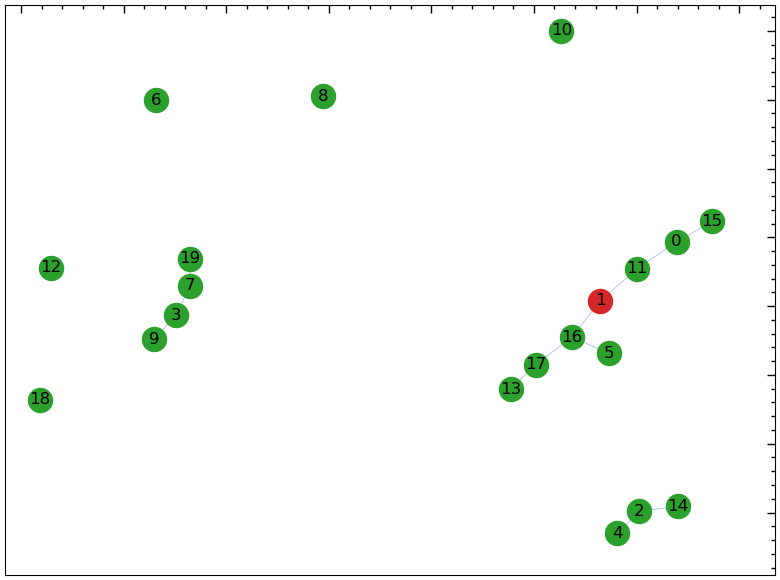

In [24]:
def infect(t,beta):
    # Propagates the infection at time "t" by one step, at rate beta over the global contact network G
    global nodes, edges
    infected= list([])
    for (i,state) in nodes.items():
        if state>=0:
            for j in neighbours[i]:
                # if j is susceptible, infect it with rate beta
                if nodes[j]==-1 and rng.random()<beta :
                    infected.append(j)
                    edges[(min(i,j),max(i,j))]=t
    for j in infected:
        #print(j)
        nodes[j]=t

def disinfect():
    # Restores the pristine contact network and node states. Useful to "reset" the system.
    global nodes, edges
    for i in nodes:
        nodes[i]=-1
    for (i,j) in edges:
        edges[(i,j)]=-1

# Infection seed: infect node "1" at time "t"=0 to start.
nodes[1]=0

3. Which individual (=node) should be immunised (=removed from the network) in order to minimise the mean attack rate? Write a (possibly greedy, not optimised) function to automatically identify this individual in an arbitary contact network.

In [3]:
def identify_individual():
    # Returns the ID of the node whose suppression will most decrease the mean attack rate
    global nodes, edges, neigbhours
    ...
    return ??


## S->I->S dynamics  

        



Now, every infected individual recovers after an infectious period of duration T=1 and is immediately susceptible again.

4. Code and display these S->I->S dynamics over 20 time units on the above random network.

In [40]:
disinfect()

# Infection dynamics
beta= 0.2

...

nodes[1]= 0
for t in range(1,20):
    infect(t,beta)

# Display the graph
def draw_graph_full_arguments(t, G, nodes, edges, pos=None):
    # draw the contact network using networkx, showing in red the infectious nodes and edges at time "t"
    if pos==None:
        pos= nx.spring_layout(G)
    nx.draw_networkx_nodes(G, pos, nodelist=[ node for node in nodes.keys() if (nodes[node]==-1 or nodes[node]>t)], node_color="tab:green")
    # YOU MAY NEED TO EDIT THE FOLLOWING LINE
    nx.draw_networkx_nodes(G, pos, nodelist=[ node for node in nodes.keys() if (nodes[node]>=0 and nodes[node]<=t)], node_color="tab:red")
    nx.draw_networkx_edges(G, pos, edgelist=edges.keys(), width=0.5, alpha=0.5,  edge_color="tab:green")
    nx.draw_networkx_edges(G, pos, edgelist=[edge for edge in edges.keys() if (edges[edge]>=0 and edges[edge]<=t)], width=5, alpha=0.5,  edge_color="tab:red")
    nx.draw_networkx_labels(G, pos)
    plt.show()
    


# Display the infection dynamics
plt.figure();
G, pos= create_graph(nodes,edges)
@interact(t=widgets.IntSlider(min=0, max=20, step=1, value=0, description="Time"))
def go(t):
    draw_graph_full_arguments(t, G, nodes, edges, pos)
    


<Figure size 800x600 with 0 Axes>

interactive(children=(IntSlider(value=0, description='Time', max=20), Output()), _dom_classes=('widget-interac…

5. Show that, instead of working with an infection probability $\beta<1$, one can consider an infection probability $\beta=1$, provided that one suitably modifies the contact network. What should the modified network be? Write a function that returns the modified edges.

In [ ]:
def modify_network(nodes,edges):
    ...
    return new_edges

6. What is the distribution of attack rates (=percentage of individuals that have been infected) in the long run, as a function of properties of the modified network?

#### Percolation

6. Starting from a fully connected network with N>>1 nodes (for example, N=100) and varying $\beta\ll1$, plot the mean attack rate vs. $\beta$. Show the existence of a transition at $\beta=\beta_c$ and make a connection with the percolation transition.

7. For $N\gg1$, plot the distribution of attack rates:
- for $\beta\ll \beta_c$
- for $\beta \simeq \beta_c$.
  
    What simple functions best describe these distributions, in your opinion?

## S->I->R->S dynamics

Henforth, after being infected (and contagious), the individuals enjoy a reprieve (=recovery period during which they are immunised and cannot be infected) of duration $T_R=2$ time units.

8. Code the associated dynamics and display the epidemic dynamics, showing individuals in their recovery period (R) in a different colour.

In [ ]:
disinfect()

# Infection dynamics
beta= 0.2
T_R= 2

...

nodes[1]= 0
for t in range(1,20):
    infect(t,beta)

# Display the graph
def draw_graph_full_arguments(t, G, nodes, edges, pos=None):
    # draw the contact network using networkx, showing in red the infectious nodes and edges at time "t"
    if pos==None:
        pos= nx.spring_layout(G)
    nx.draw_networkx_nodes(G, pos, nodelist=[ node for node in nodes.keys() if (nodes[node]==-1 or nodes[node]>t)], node_color="tab:green")
    # YOU MAY NEED TO EDIT THE FOLLOWING LINES
    nx.draw_networkx_nodes(G, pos, nodelist=[ node for node in nodes.keys() if (nodes[node]>=0 and nodes[node]<=t)], node_color="tab:red")
    nx.draw_networkx_edges(G, pos, edgelist=edges.keys(), width=0.5, alpha=0.5,  edge_color="tab:green")
    nx.draw_networkx_edges(G, pos, edgelist=[edge for edge in edges.keys() if (edges[edge]>=0 and edges[edge]<=t)], width=5, alpha=0.5,  edge_color="tab:red")
    nx.draw_networkx_labels(G, pos)
    plt.show()
    


# Display the infection dynamics
plt.figure();
G, pos= create_graph(nodes,edges)
@interact(t=widgets.IntSlider(min=0, max=20, step=1, value=0, description="Time"))
def go(t):
    draw_graph_full_arguments(t, G, nodes, edges, pos)
    

#### Importance of the topology of the network

Finally, we turn to our global goal, namely, to find the relevance of the network properties on the disease spreading dynamics.

9. Explore the S->I->R->S dynamics on different types of networks, including:
- a fully connected network
- a small-world network model
- ...
If you do not see dramatic differences, you may drawn inspiration from the following paper to study appropriate networks.
Guillermo Abramson and Marcelo Kuperman, "Small world effect in an epidemiological model", Phys. Rev. Lett. (2001), https://arxiv.org/pdf/nlin/0010012

Plot the number of infected individuals (I) as a function of time.